### Análise Exploratória de Dados (EDA) aprofundada do projeto, após a EDA preliminar e o pré-processamento já realizado.

##### Aqui, vamos buscar entender quais são os pontos de atenção de fato para modelar o nosso projeto

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

Como um problema do csv em manter o tratamento das datas, precisamos fazer aqui novamente. Todavia, não será um problema dos grandes, já que estamos trabalhando com poucas colunas de data relevantes. Pensando em escala, talvez seja melhor rodar em parquet mesmo.

In [22]:
df_final = pd.read_csv("../data/processed/base_unificada.csv")

df_final["order_delivered_customer_date"] = pd.to_datetime(df_final["order_delivered_customer_date"])
df_final["order_estimated_delivery_date"] = pd.to_datetime(df_final["order_estimated_delivery_date"])
df_final["order_purchase_timestamp"] = pd.to_datetime(df_final["order_purchase_timestamp"])

Aqui medimos quantos % dos pedidos entregues chegaram depois do prazo estimado.

In [23]:
atrasado = df_final[df_final["dias_atrasados"] > 0]
    
print(f"Proporção de atrasados: {len(atrasado) / len(df_final):.2%}")

Proporção de atrasados: 7.91%


Entre os atrasados, conseguimos ter melhor uma noção de magnitude. Detalhe para o "max", que chega em um atraso de quase meio ano.

In [24]:
atrasado["dias_atrasados"].describe()

count    8714.000000
mean        9.427868
std        13.804352
min         0.002500
25%         1.858368
50%         5.777894
75%        11.775825
max       188.975081
Name: dias_atrasados, dtype: float64

Aqui, confirmamos que alguns valores não estão faltantes e, com a média desses atributos, o valor de dias_atrasado em -11 tem média negativa mesmo em geral, já que a maioria não atrasa, mas sim chega no prazo.

In [25]:
colunas_interesse = ['dias_atrasados', 'price', 'freight_value']

print("Médias dos Atributos")
print(df_final[colunas_interesse].mean())

print("\nValores Faltantes")
print(df_final[colunas_interesse].isna().sum())

Médias dos Atributos
dias_atrasados    -11.331987
price             119.977937
freight_value      19.948869
dtype: float64

Valores Faltantes
dias_atrasados    0
price             0
freight_value     0
dtype: int64


Nessa Matriz de Correlação, só confirmamos a hipótese de que o peso do produto se relaciona com o preço do frete. Essa matriz nos ajuda a compreender quais colunas se relacionam com quais, e são um bom indicador para a modelagem futura.

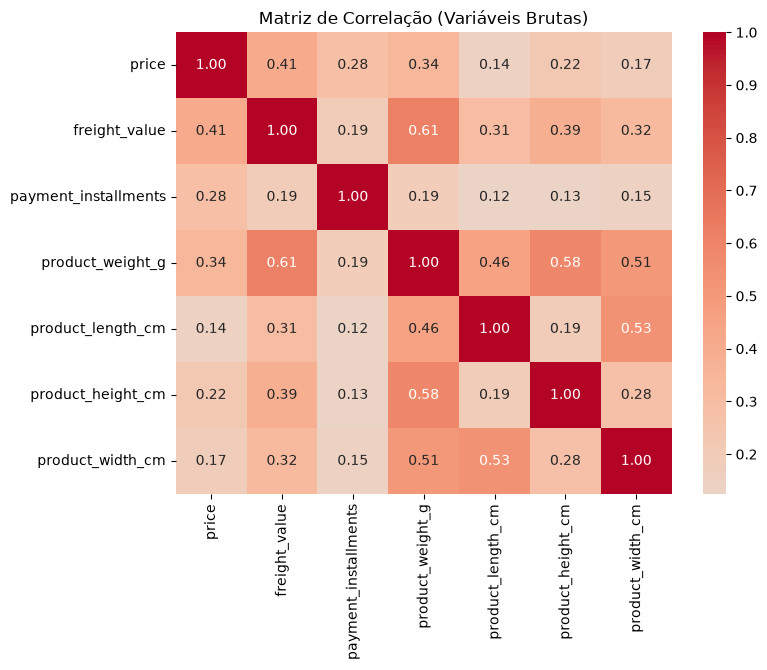

In [26]:
colunas_brutas = ['price', 'freight_value', 'payment_installments', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

matriz_corr_bruta = df_final[colunas_brutas].corr()

plt.figure(figsize=(8,6))
sns.heatmap(matriz_corr_bruta, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matriz de Correlação (Variáveis Brutas)")
plt.show()

Pensando em frete, visei buscar os outliers usando o IQR, e vemos um valor meio assustador. 11296 itens possuem frete bem acima do esperado pra faixa de preço deles, e a resposta pode ser pelas dimensões do produto, peso, tamanho, etc...

In [27]:
Q1 = df_final["freight_value"].quantile(0.25)
Q3 = df_final["freight_value"].quantile(0.75)
IQR = Q3 - Q1
limite = Q3 + 1.5 * IQR

len(df_final[df_final["freight_value"] > limite])

11296

Quanto a um padrão temporal, quando olhamos o número de compra por mês, dá pra notar bem a sazonalidade do e-commerce. Em novembro de 2017, o número de compras atingiu o seu máximo, em 8475.

In [28]:
df_final["mes_compra"] = df_final["order_purchase_timestamp"].dt.to_period("M")
df_final["mes_compra"].value_counts().sort_index()

mes_compra
2016-09       3
2016-10     313
2016-12       1
2017-01     913
2017-02    1858
2017-03    2897
2017-04    2569
2017-05    4003
2017-06    3489
2017-07    4416
2017-08    4797
2017-09    4737
2017-10    5214
2017-11    8474
2017-12    6187
2018-01    8037
2018-02    7518
2018-03    8017
2018-04    7827
2018-05    7810
2018-06    7007
2018-07    6960
2018-08    7142
Freq: M, Name: count, dtype: int64

Quanto à segmentação por estado, é possível obter diante um groupby entre esta_atrasado e customer_state, que a taxa de atrasos NÃO é igual em todo lugar, e estados do nordeste possuem taxa bem maior do que estados do sul e do sudeste do Brasil, por exemplo.

In [29]:
df_final["esta_atrasado"] = df_final["dias_atrasados"] > 0
df_final.groupby("customer_state")["esta_atrasado"].mean()

customer_state
AC    0.032967
AL    0.241218
AM    0.042945
AP    0.049383
BA    0.136845
CE    0.152875
DF    0.074310
ES    0.122247
GO    0.078612
MA    0.203750
MG    0.054429
MS    0.108508
MT    0.067502
PA    0.124288
PB    0.112628
PE    0.101947
PI    0.154876
PR    0.047796
RJ    0.129746
RN    0.103647
RO    0.040293
RR    0.108696
RS    0.068808
SC    0.096168
SE    0.162667
SP    0.057686
TO    0.122581
Name: esta_atrasado, dtype: float64

Aqui, uma análise bem interessante dessa etapa mais aprofundada da EDA, sendo uma segmentação por vendedor relacionado à taxa de entrega dos produtos, ou seja, esses são os vendedores com as piores taxas de "estarem dentro do prazo". Isso é medido pela jornada toda até chegar ao cliente, desde o momento em que ele realiza a compra. É um histórico de confiabilidade de entrega do vendedor.

In [30]:
taxa_por_vendedor = df_final.groupby("seller_id")["esta_atrasado"].mean()

contagem_por_vendedor = df_final.groupby("seller_id")["esta_atrasado"].count()
vendedores_com_volume = contagem_por_vendedor[contagem_por_vendedor >= 20].index

taxa_por_vendedor_filtrada = taxa_por_vendedor[vendedores_com_volume]
taxa_por_vendedor_filtrada.sort_values(ascending=False).head(10)


seller_id
2709af9587499e95e803a6498a5a56e9    0.500000
f76a3b1349b6df1ee875d1f3fa4340f0    0.375000
821fb029fc6e495ca4f08a35d51e53a5    0.360000
ede0c03645598cdfc63ca8237acbe73d    0.340426
54965bbe3e4f07ae045b90b0b8541f52    0.320988
ad781527c93d00d89a11eecd9dcad7c1    0.315789
835f0f7810c76831d6c7d24c7a646d4d    0.312500
7f152321c60a266edc53af1925ef96c1    0.300000
2a1348e9addc1af5aaa619b1a3679d6b    0.294118
4e5725ba188db8252977a4f0227bd462    0.291667
Name: esta_atrasado, dtype: float64